In [2]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [14]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def load_txt_file(rootpath, model_name):
    txt_path = os.path.join(rootpath, model_name, "scores.txt")
    if not os.path.exists(txt_path):
        raise FileNotFoundError(f"File not found: {txt_path}")

    scores = []
    labels = []
    with open(txt_path, 'r') as fh:
        for line in fh:
            parts = line.strip().split()
            if len(parts) != 3:
                continue  # skip malformed lines

            _, score, label = parts
            score = score.strip("[]")
            scores.append(float(score))
            labels.append(int(label))

    scores = np.array(scores)
    labels = np.array(labels)
    return scores, labels

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    
def plot_scores_distribution(scores, labels):
    # Split real/fake
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    print(f"Loaded {len(scores)} samples")
    print(f"Real mean score: {real_scores.mean():.4f}")
    print(f"Fake mean score: {fake_scores.mean():.4f}\n")

    # Plot
    plt.figure(figsize=(6, 4))
    plt.hist(real_scores, bins=100, alpha=0.5, density=True)
    plt.hist(fake_scores, bins=100, alpha=0.5, density=True)
    plt.xlabel("Score")
    plt.ylabel("Density")
    plt.title(f"Score Distribution")
    plt.legend(["Real (0)", "Fake (1)"])
    plt.show()

def plot_expert_stats(rootpath,
                      model_name,
                      stat="gating",
                      expert_labels=None):

    base_path = os.path.join(rootpath, model_name)

    global_path = os.path.join(base_path, f"{stat}_mean_global.npy")
    real_path   = os.path.join(base_path, f"{stat}_mean_real.npy")
    spoof_path  = os.path.join(base_path, f"{stat}_mean_fake.npy")

    global_w = np.load(global_path).flatten()
    real_w   = np.load(real_path).flatten()
    spoof_w  = np.load(spoof_path).flatten()

    if expert_labels is not None:
        n_experts = len(expert_labels)
        if len(global_w) != n_experts:
            raise ValueError(
                f"Mismatch: loaded stats have {len(global_w)} experts "
                f"but expert_labels has {n_experts}")
    else:
        n_experts = len(global_w)
        expert_labels = [f"E{i}" for i in range(n_experts)]

    fig, axes = plt.subplots(1, 3, figsize=(4*n_experts/2 + 6, 4), sharey=True)

    if stat == "gating":
        fig.suptitle("Gating Weights")
    elif stat == "weighted":
        fig.suptitle("Gating × Expert Logits")
    else:
        fig.suptitle("Expert Logits")

    titles = ["Avg global", "Avg real", "Avg fake"]
    data   = [global_w, real_w, spoof_w]
    colors = ["blue", "pink", "green"]

    for ax, weights, title, color in zip(axes, data, titles, colors):
        ax.bar(range(n_experts), weights, color=color)
        ax.set_title(title)
        ax.set_xticks(range(n_experts))
        ax.set_xticklabels(expert_labels, rotation=45)
        if stat == 'gating':
            ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Value")

    plt.tight_layout()
    plt.show()

    return data


In [15]:
def compute_res_and_plot(rootpath, model_name, expert_labels, distr=False, plot=True):
    scores, labels = load_txt_file(rootpath, model_name)
    
    print("\nIndividual Experts' Performance:")
    experts_scores = np.load(os.path.join(rootpath, model_name, "expert_all.npy"))
    for i in range(experts_scores.shape[1]):
        print_metrics(experts_scores[:, i], labels)    
    print("\nMoE Performance:")
    print_metrics(scores, labels)

    if distr:
        plot_scores_distribution(scores, labels)
        
    if plot:
        out_e = plot_expert_stats(rootpath, model_name, stat= 'expert', expert_labels=expert_labels)
        out_g = plot_expert_stats(rootpath, model_name, stat= 'gating', expert_labels=expert_labels)
        out_w = plot_expert_stats(rootpath, model_name, stat= 'weighted', expert_labels=expert_labels)
        return out_e, out_g, out_w

# Re-trained last expert, now is 'energy inconsistency'


Individual Experts' Performance:
AUC: 47.59%, EER: 51.90%
AUC: 30.90%, EER: 64.03%
AUC: 52.68%, EER: 50.01%
AUC: 77.23%, EER: 30.35%
AUC: 82.19%, EER: 25.04%

MoE Performance:
AUC: 76.31%, EER: 29.12%
Loaded 19171 samples
Real mean score: -4.0815
Fake mean score: 2.0541



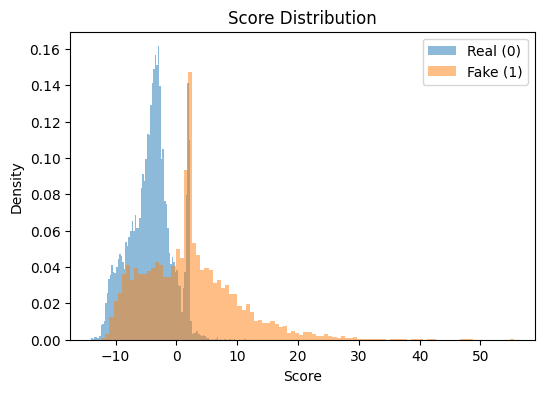

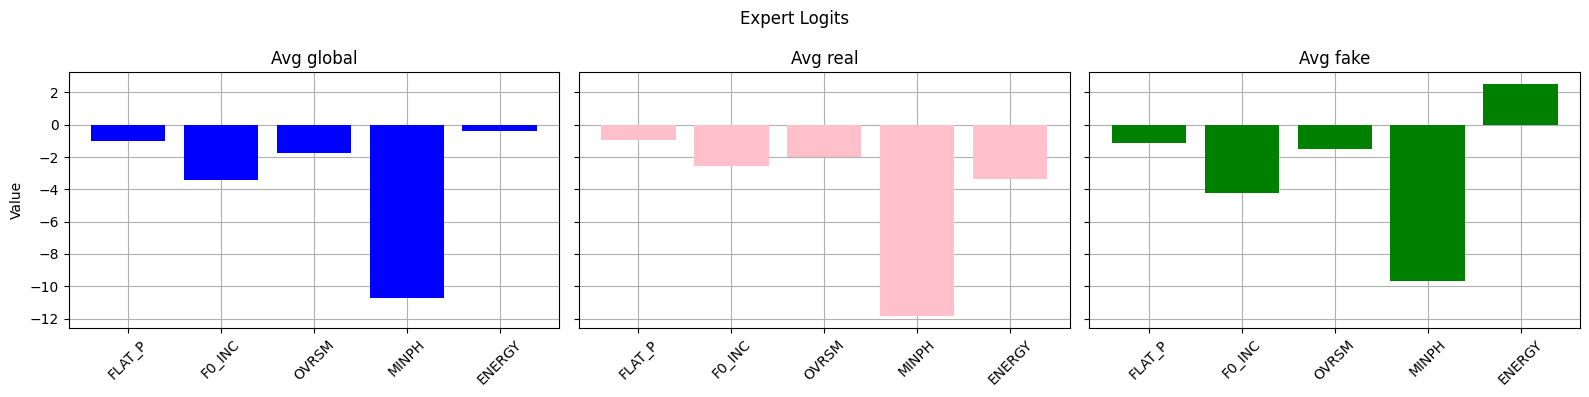

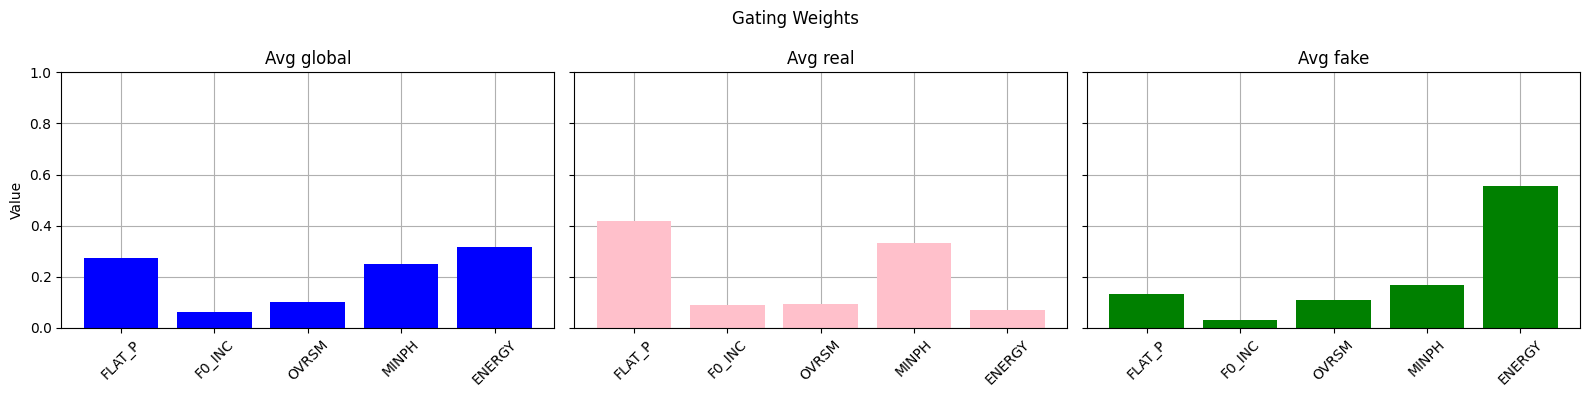

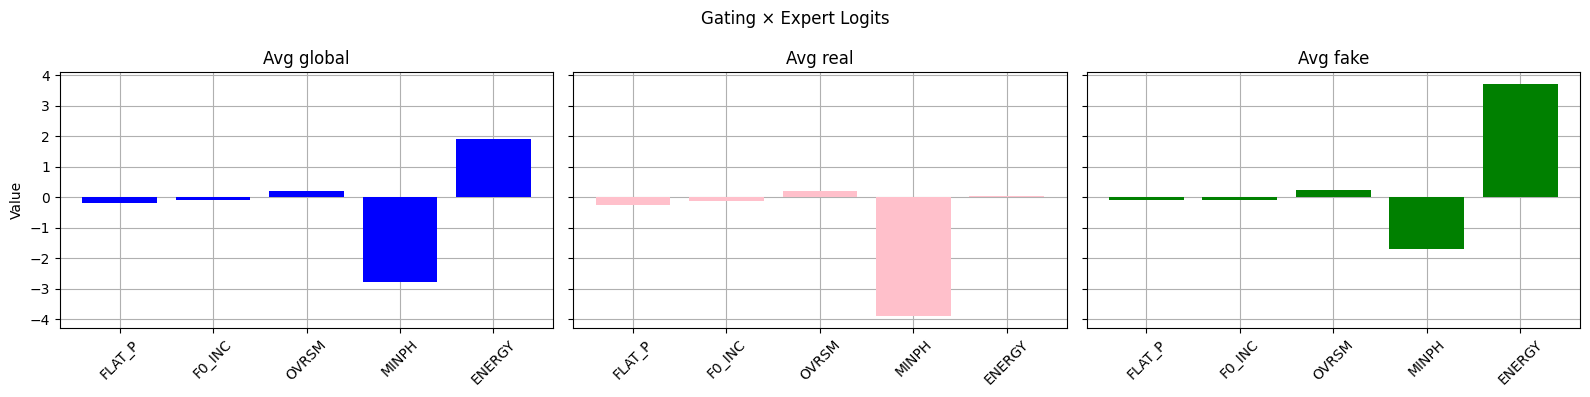

In [16]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/ALL"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

# Per generator analysis

A01

Individual Experts' Performance:
AUC: 72.92%, EER: 31.99%
AUC: 32.78%, EER: 62.91%
AUC: 79.52%, EER: 30.07%
AUC: 73.13%, EER: 33.37%
AUC: 79.96%, EER: 25.29%

MoE Performance:
AUC: 81.07%, EER: 24.76%
Loaded 1898 samples
Real mean score: -4.0981
Fake mean score: -0.0330



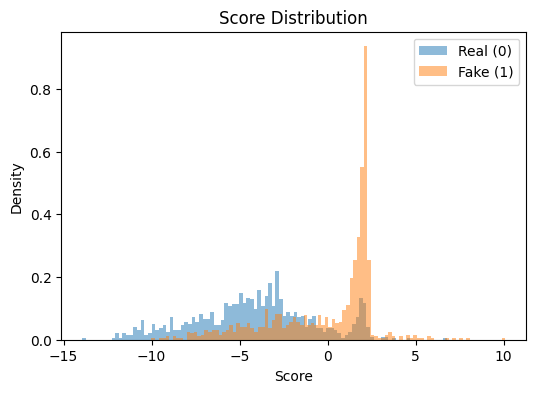

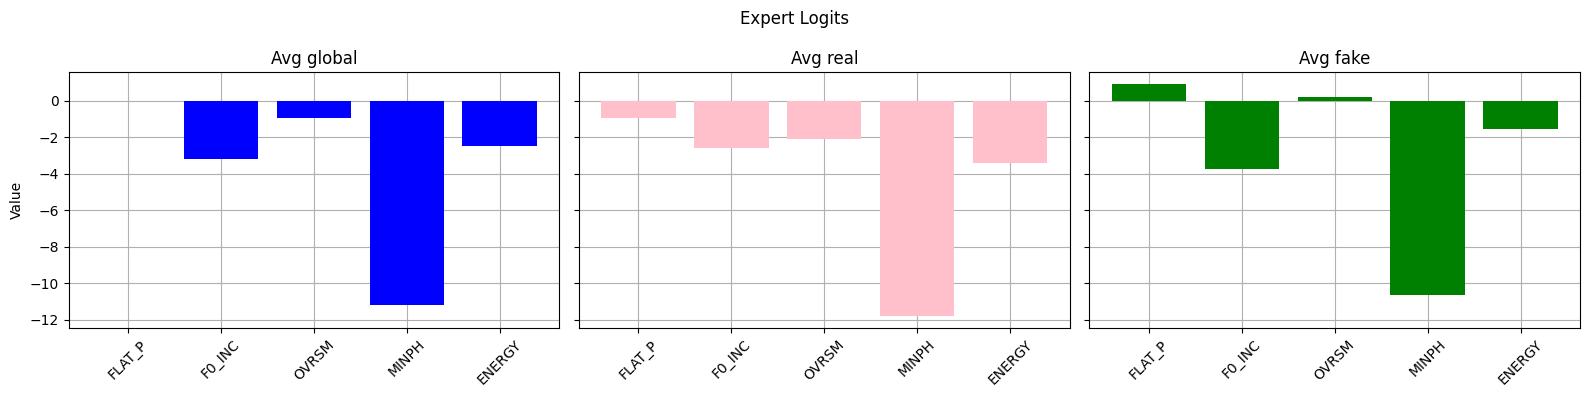

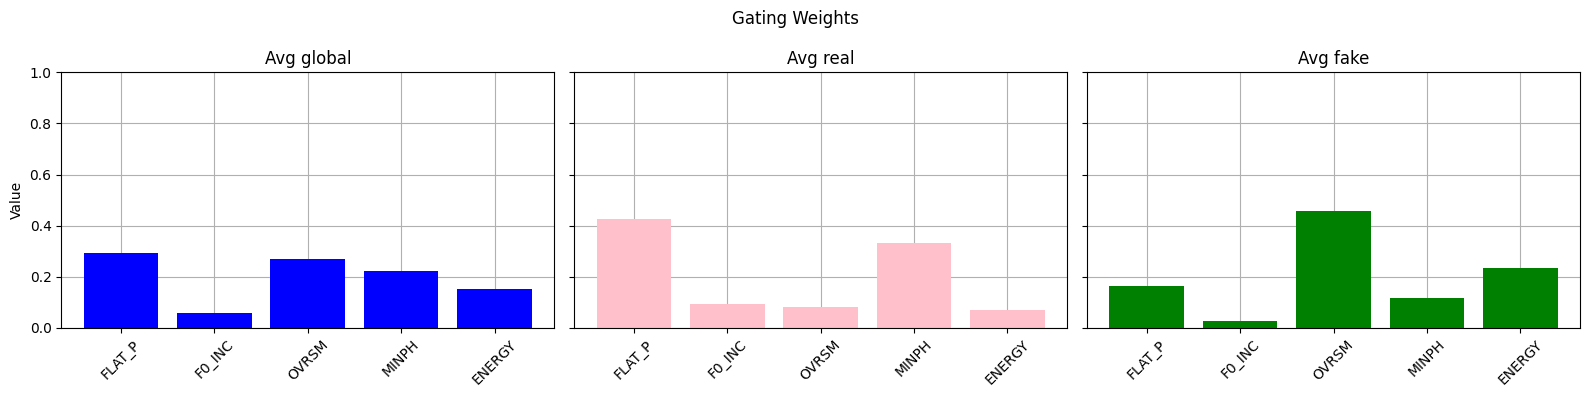

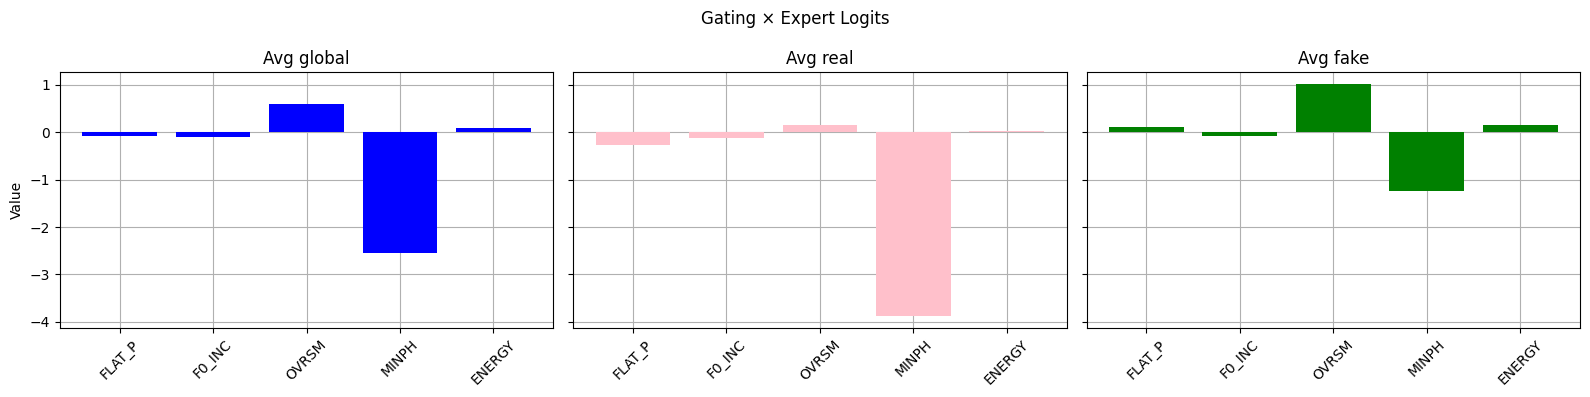

-----------------------------------
A02

Individual Experts' Performance:
AUC: 31.26%, EER: 63.02%
AUC: 17.31%, EER: 73.75%
AUC: 66.08%, EER: 39.43%
AUC: 72.41%, EER: 34.75%
AUC: 71.92%, EER: 32.20%

MoE Performance:
AUC: 62.80%, EER: 39.96%
Loaded 1926 samples
Real mean score: -4.0981
Fake mean score: -1.0324



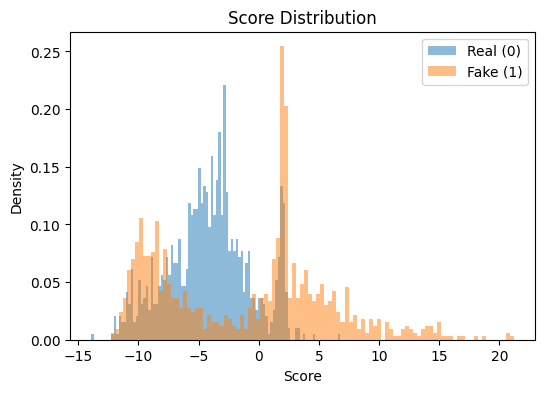

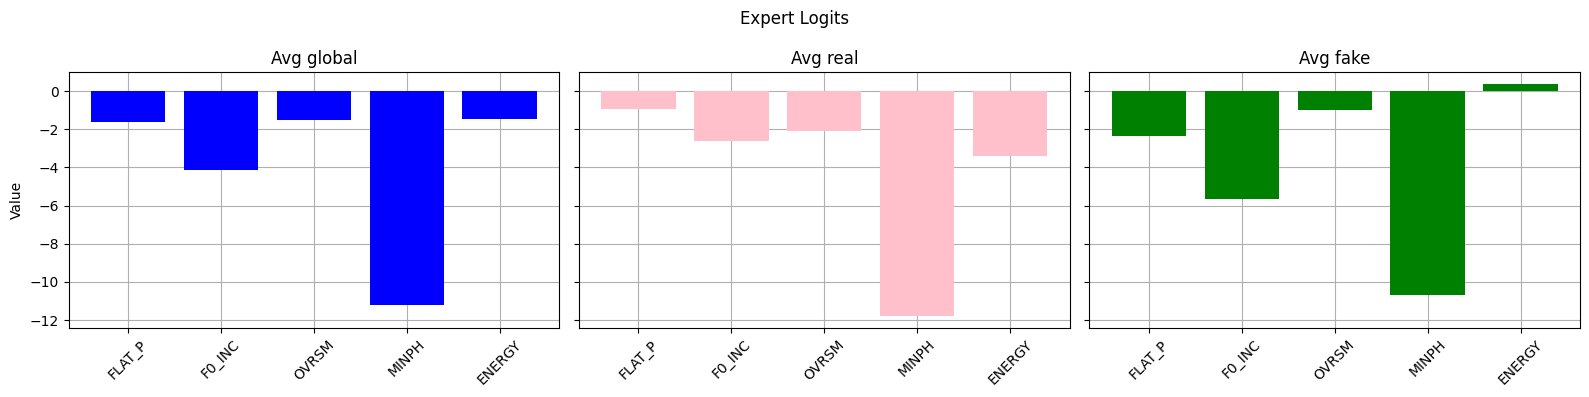

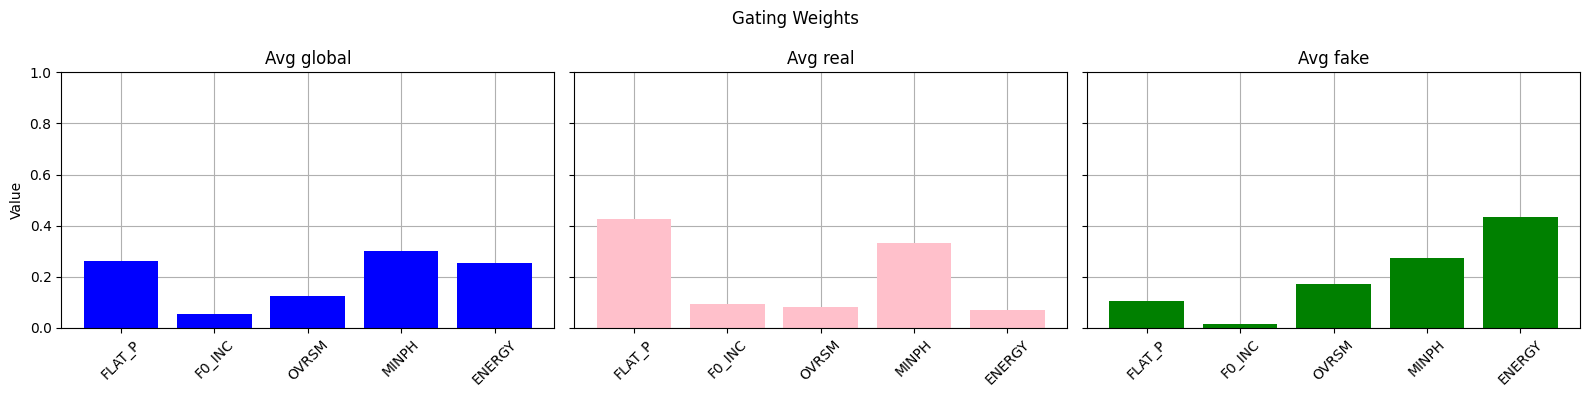

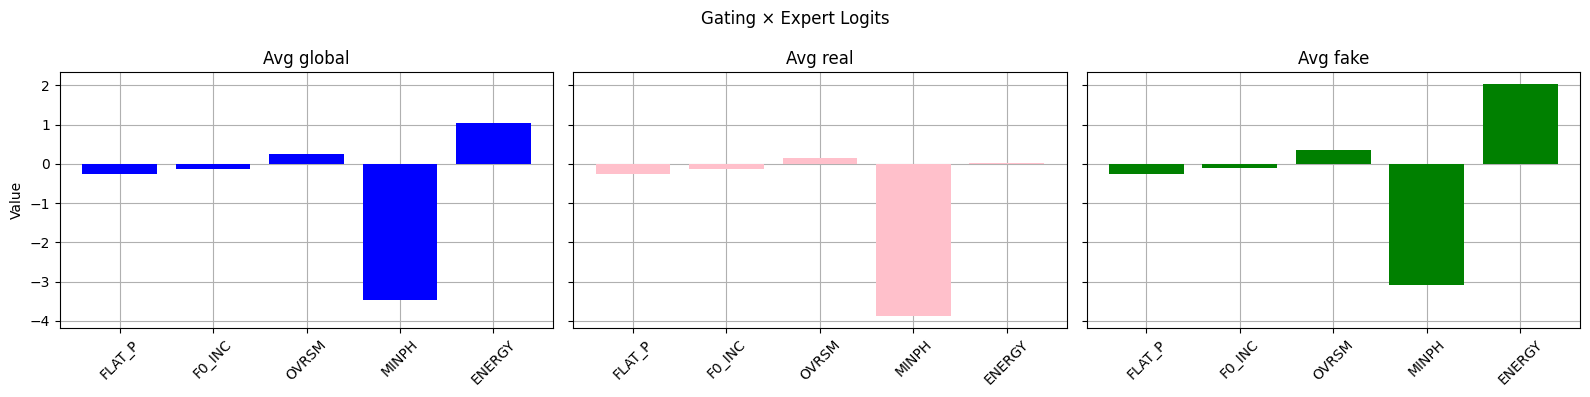

-----------------------------------
A03

Individual Experts' Performance:
AUC: 42.46%, EER: 56.11%
AUC: 22.00%, EER: 69.71%
AUC: 63.72%, EER: 40.60%
AUC: 88.08%, EER: 19.98%
AUC: 96.54%, EER: 9.14%

MoE Performance:
AUC: 89.82%, EER: 14.56%
Loaded 1931 samples
Real mean score: -4.0981
Fake mean score: 2.5090



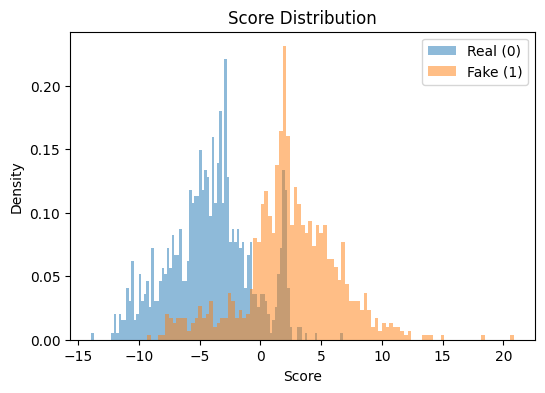

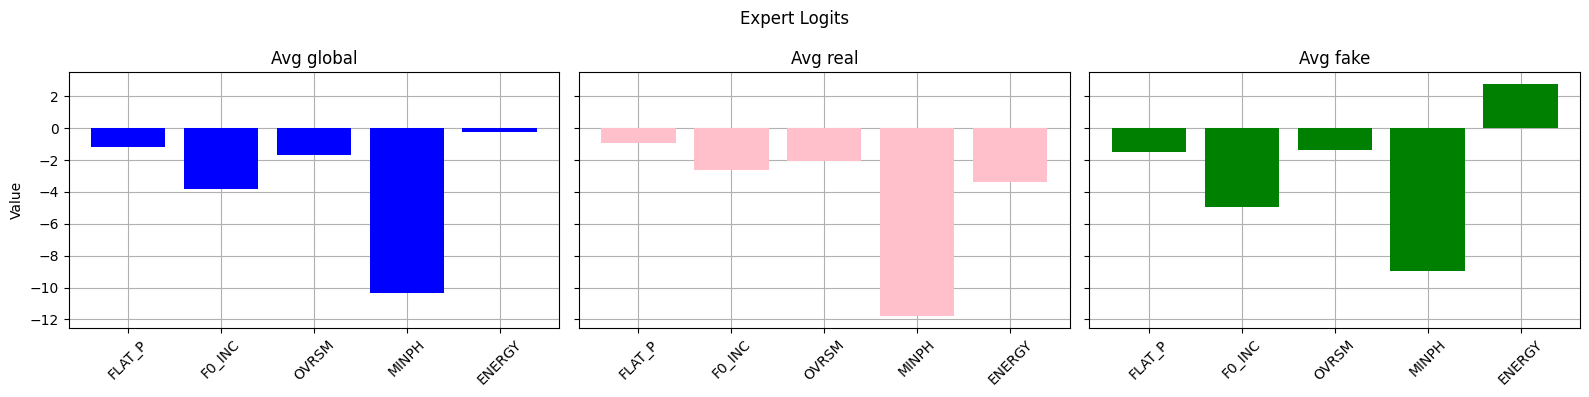

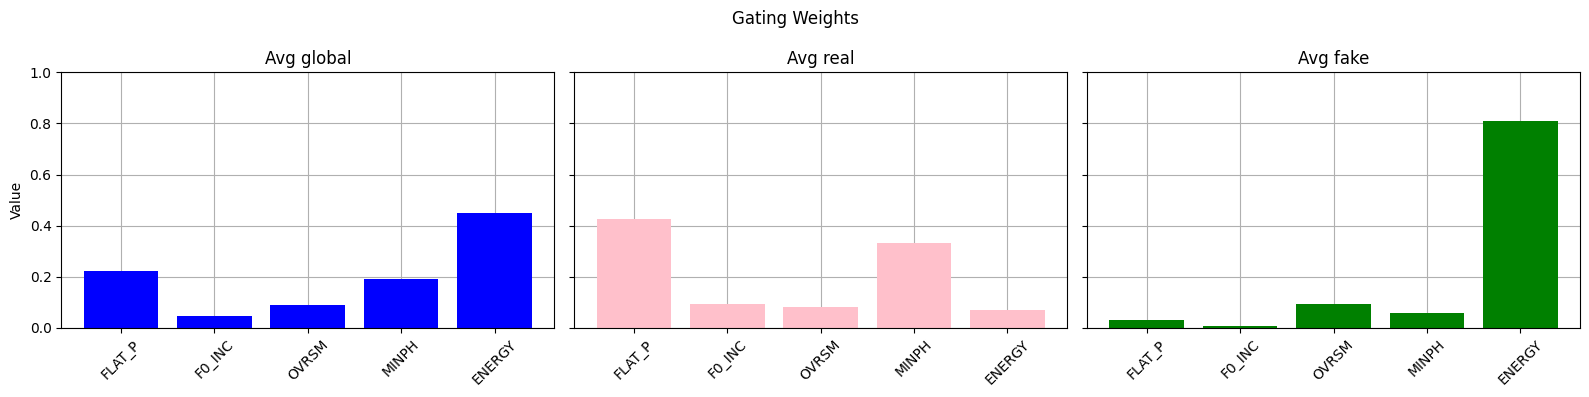

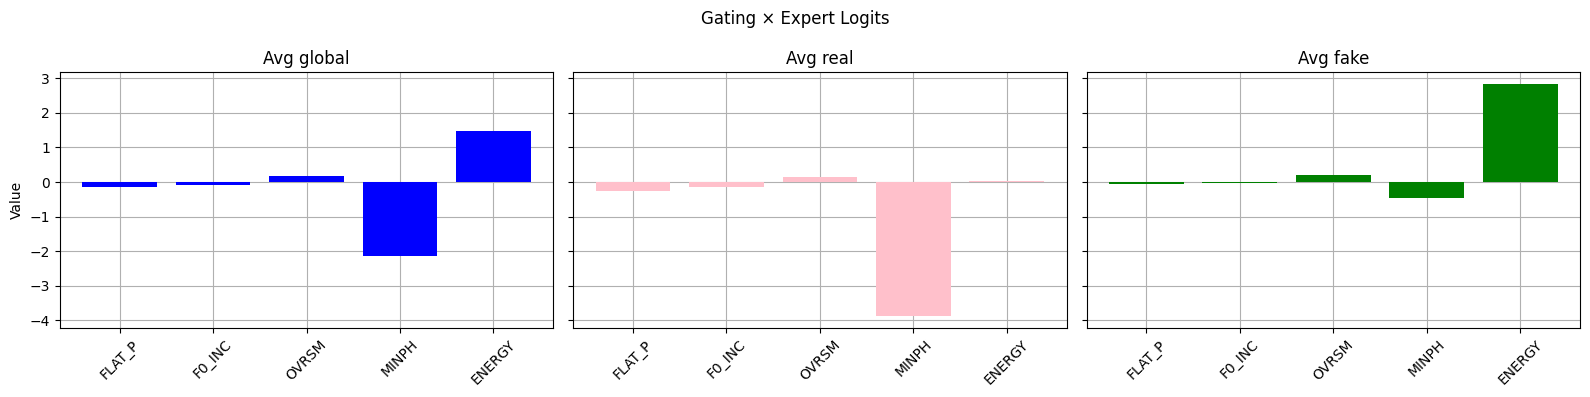

-----------------------------------
A04

Individual Experts' Performance:
AUC: 63.55%, EER: 40.70%
AUC: 72.36%, EER: 34.43%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 89.75%, EER: 19.34%

MoE Performance:
AUC: 90.21%, EER: 19.66%
Loaded 1880 samples
Real mean score: -4.0981
Fake mean score: 6.0657



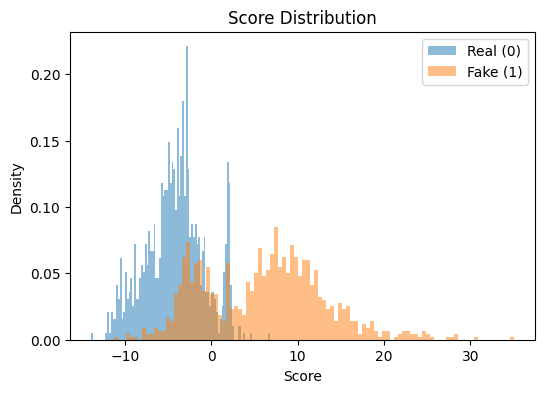

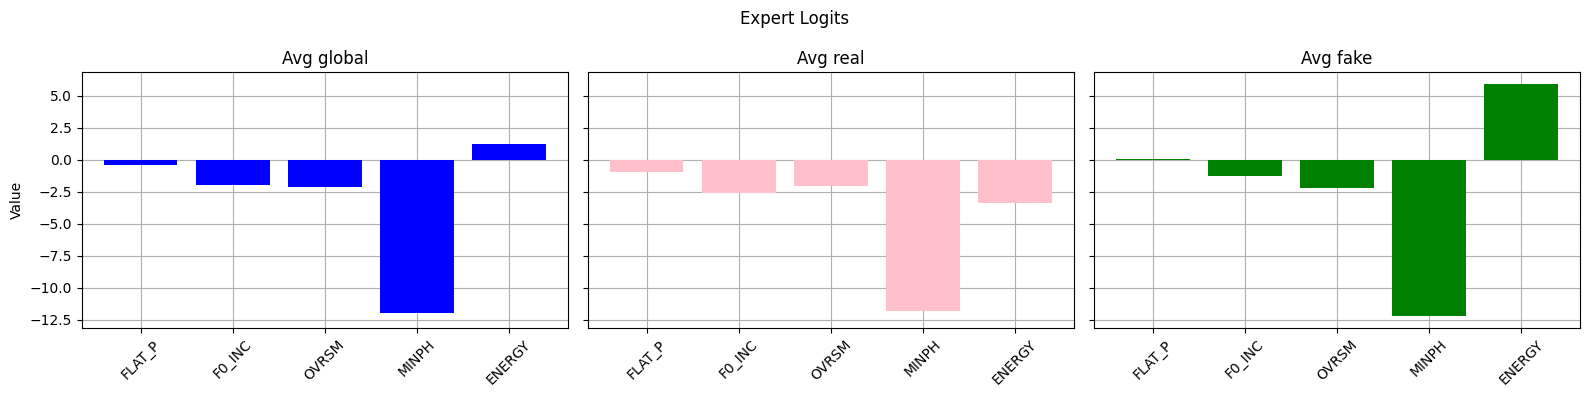

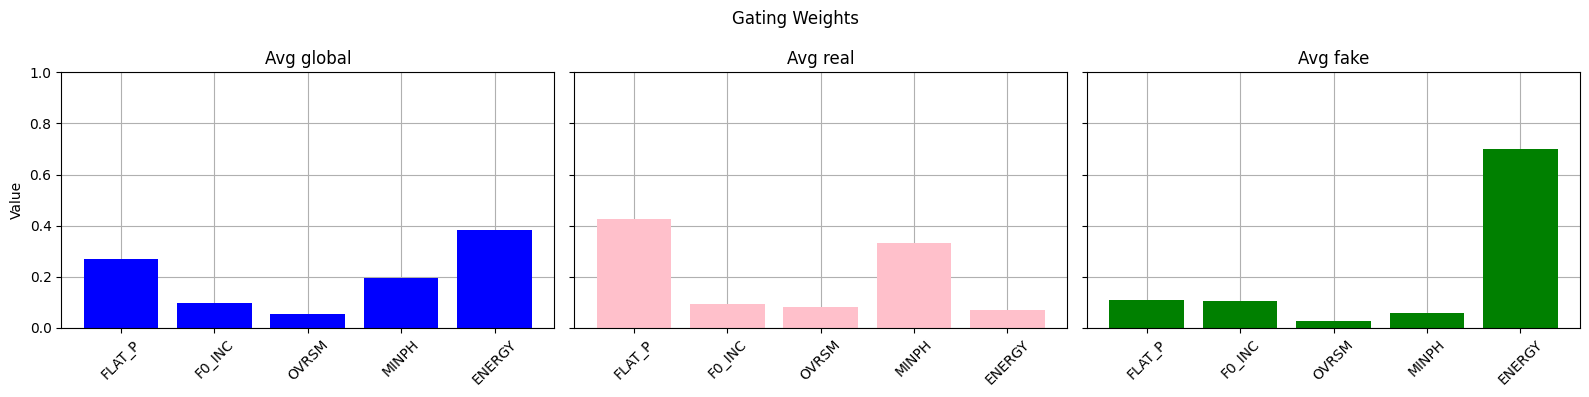

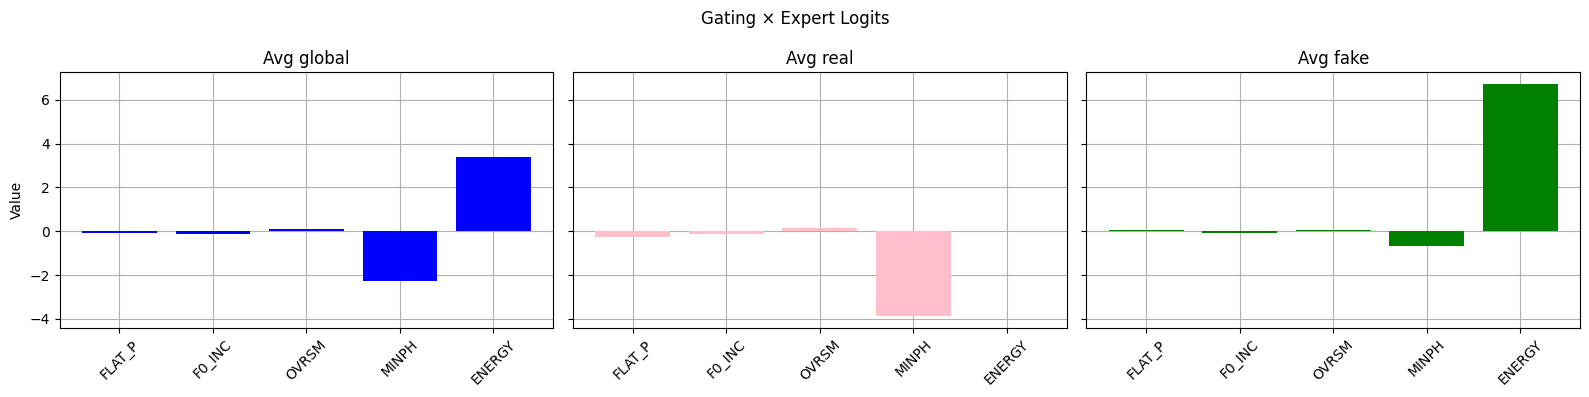

-----------------------------------
A07

Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 63.86%, EER: 38.79%

MoE Performance:
AUC: 37.68%, EER: 63.12%
Loaded 1940 samples
Real mean score: -4.0981
Fake mean score: -5.3140



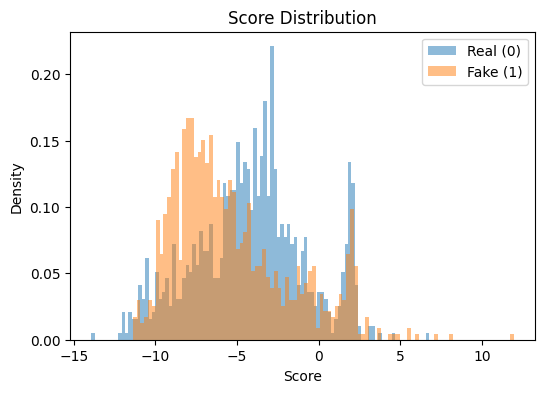

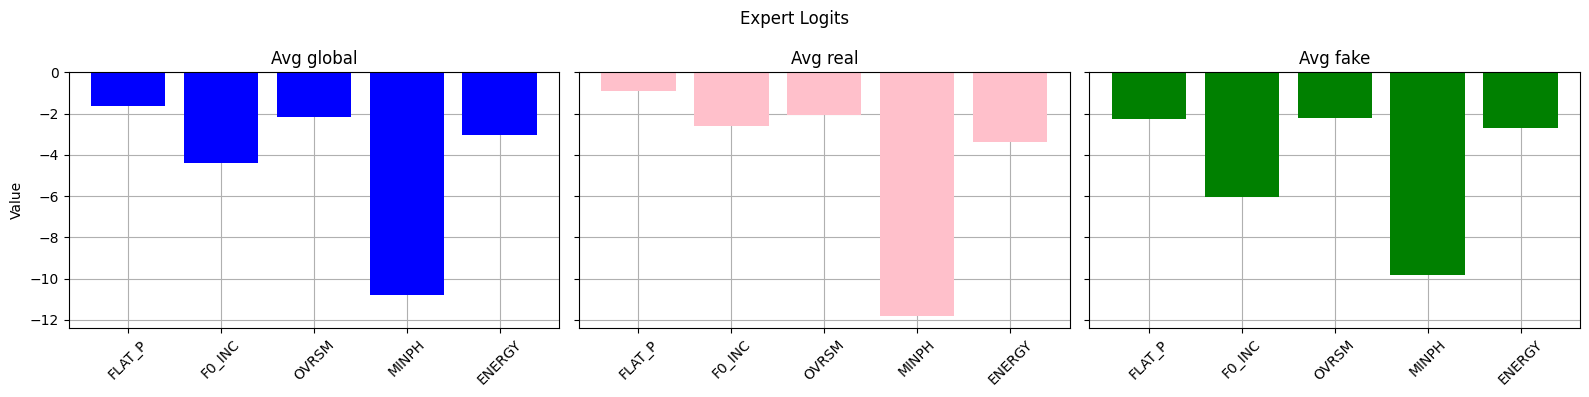

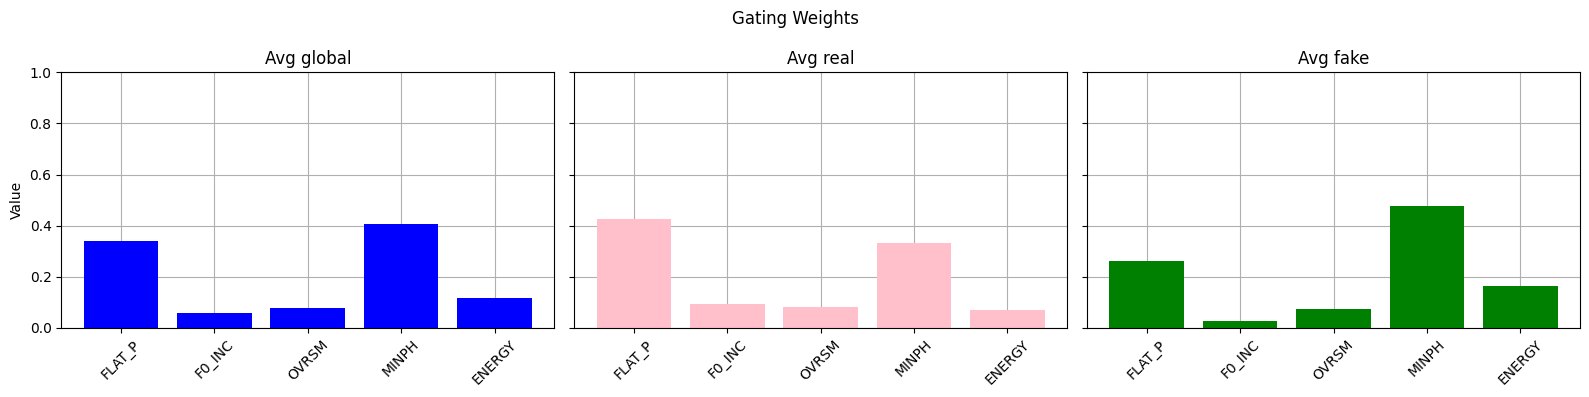

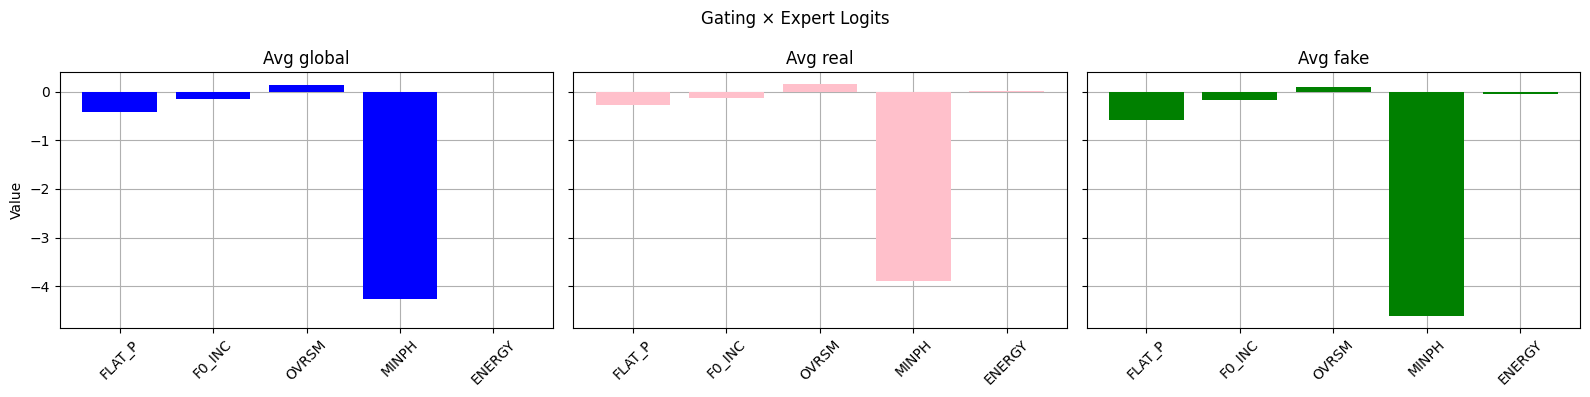

-----------------------------------
A08

Individual Experts' Performance:
AUC: 63.52%, EER: 39.64%
AUC: 26.31%, EER: 67.91%
AUC: 54.58%, EER: 48.78%
AUC: 97.17%, EER: 8.82%
AUC: 96.96%, EER: 8.40%

MoE Performance:
AUC: 92.62%, EER: 14.13%
Loaded 1933 samples
Real mean score: -4.0981
Fake mean score: 3.7455



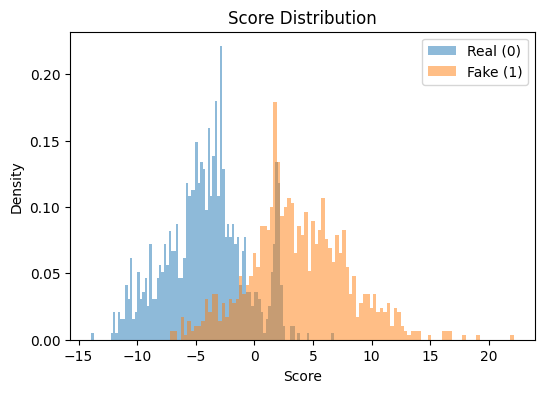

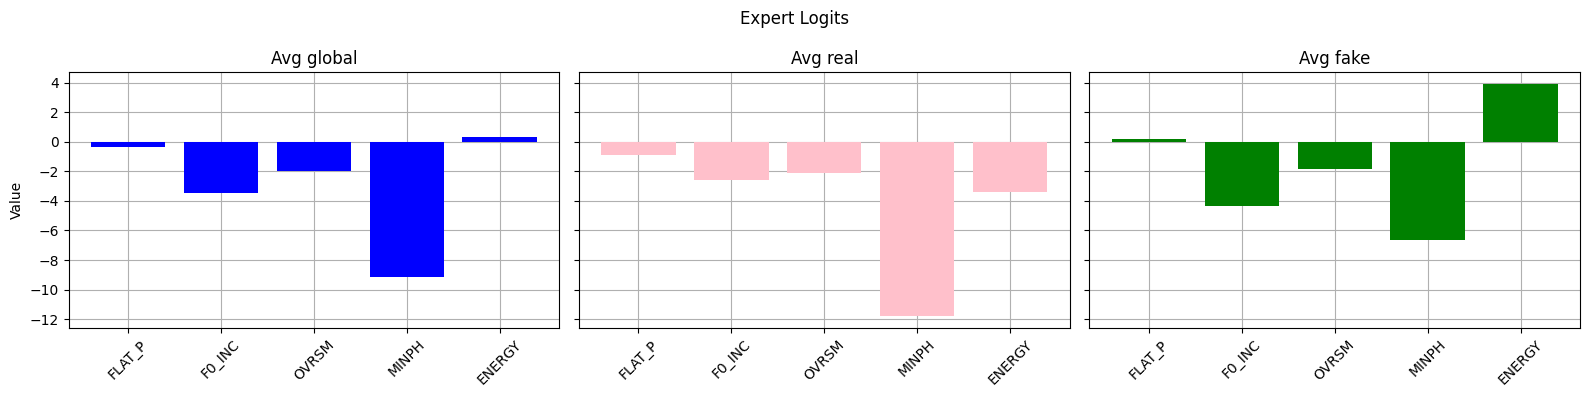

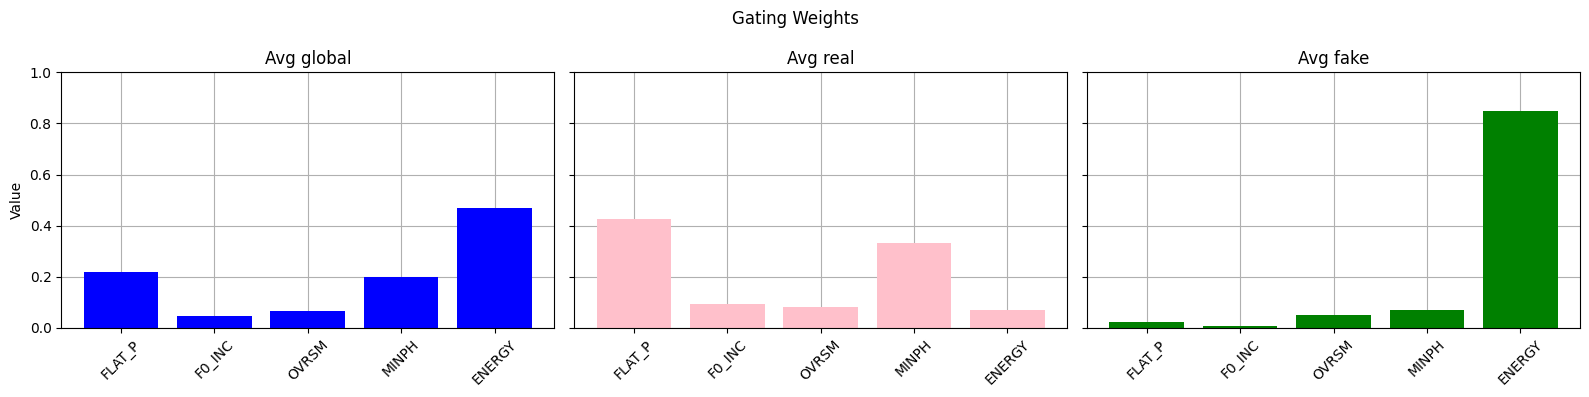

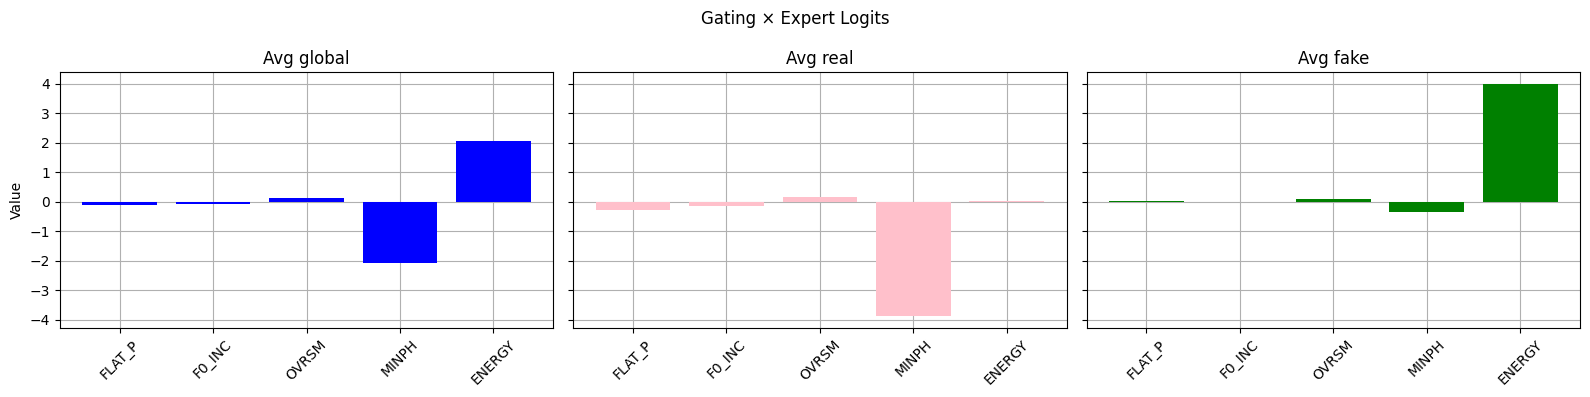

-----------------------------------
A09

Individual Experts' Performance:
AUC: 22.77%, EER: 70.46%
AUC: 15.13%, EER: 75.77%
AUC: 74.59%, EER: 33.90%
AUC: 98.97%, EER: 4.68%
AUC: 97.23%, EER: 8.61%

MoE Performance:
AUC: 94.63%, EER: 12.11%
Loaded 1939 samples
Real mean score: -4.0981
Fake mean score: 10.8509



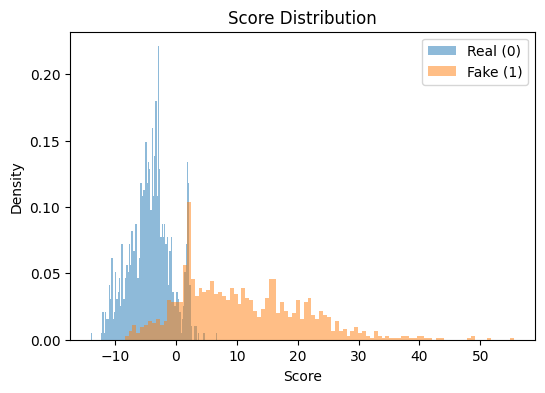

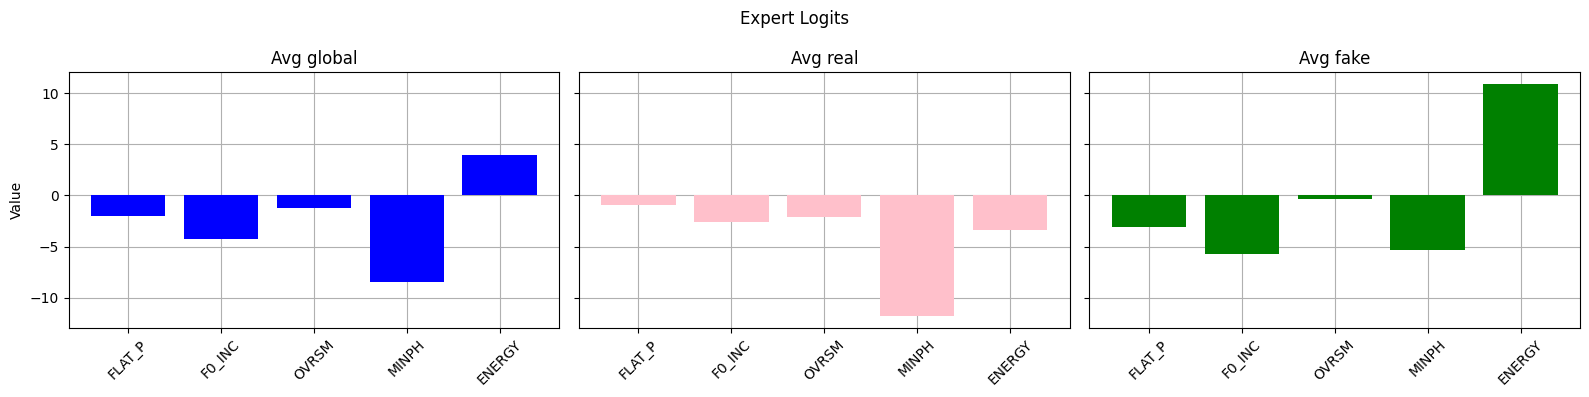

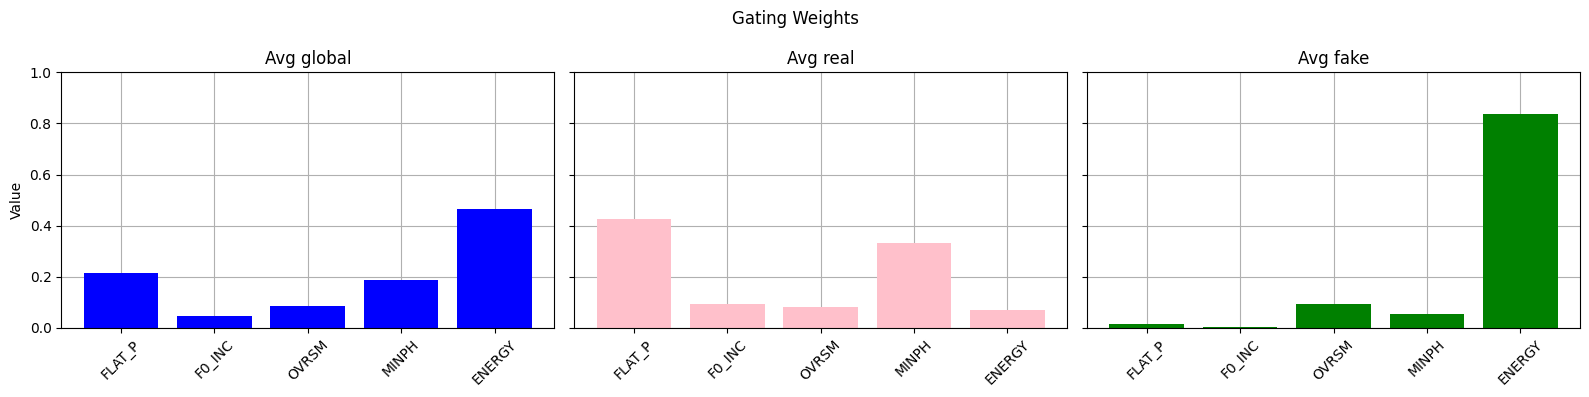

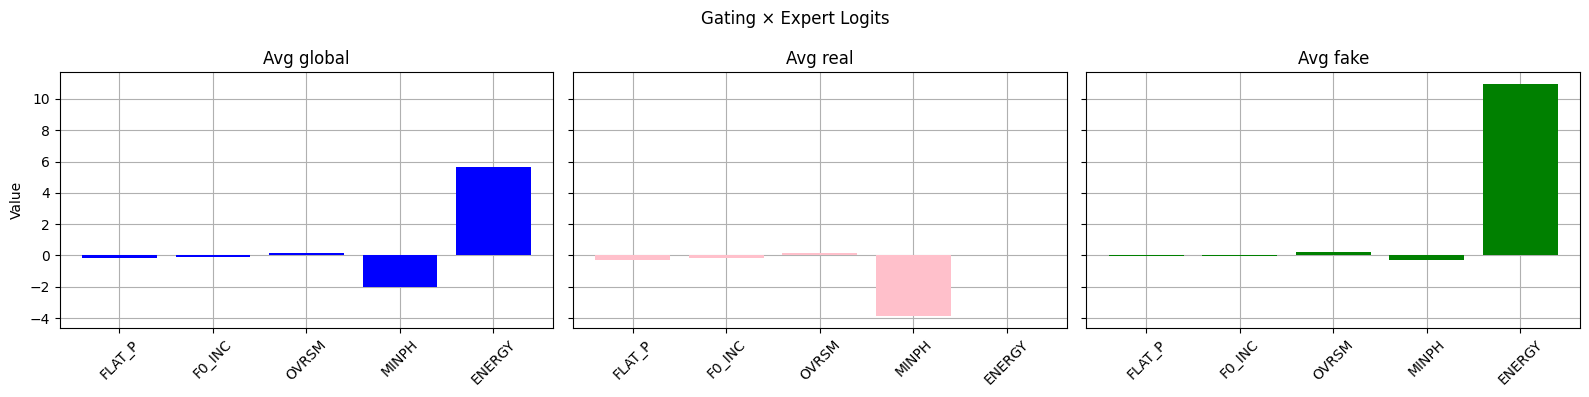

-----------------------------------
A10

Individual Experts' Performance:
AUC: 50.32%, EER: 48.99%
AUC: 38.14%, EER: 58.24%
AUC: 41.40%, EER: 57.60%
AUC: 68.30%, EER: 36.03%
AUC: 58.14%, EER: 43.89%

MoE Performance:
AUC: 50.32%, EER: 49.52%
Loaded 1898 samples
Real mean score: -4.0981
Fake mean score: -4.0514



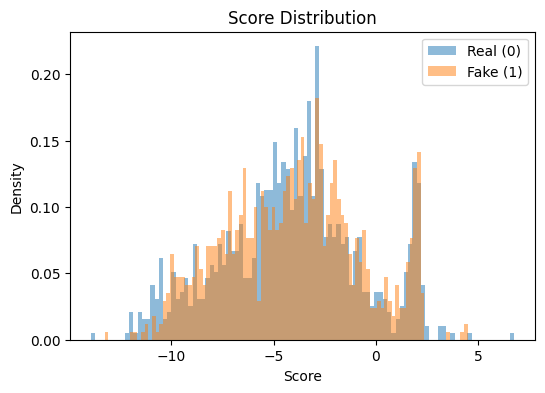

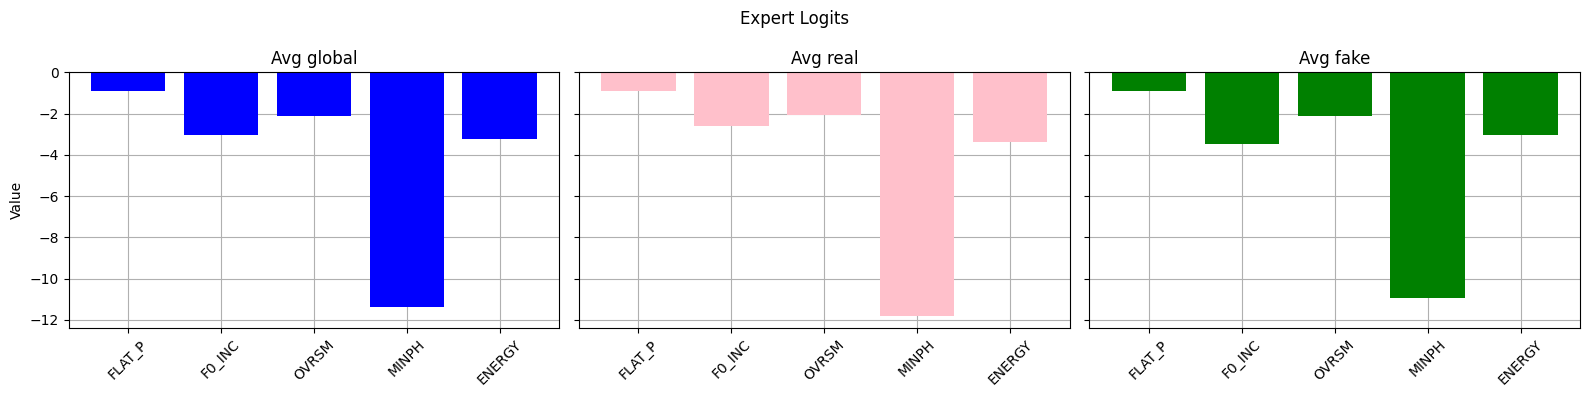

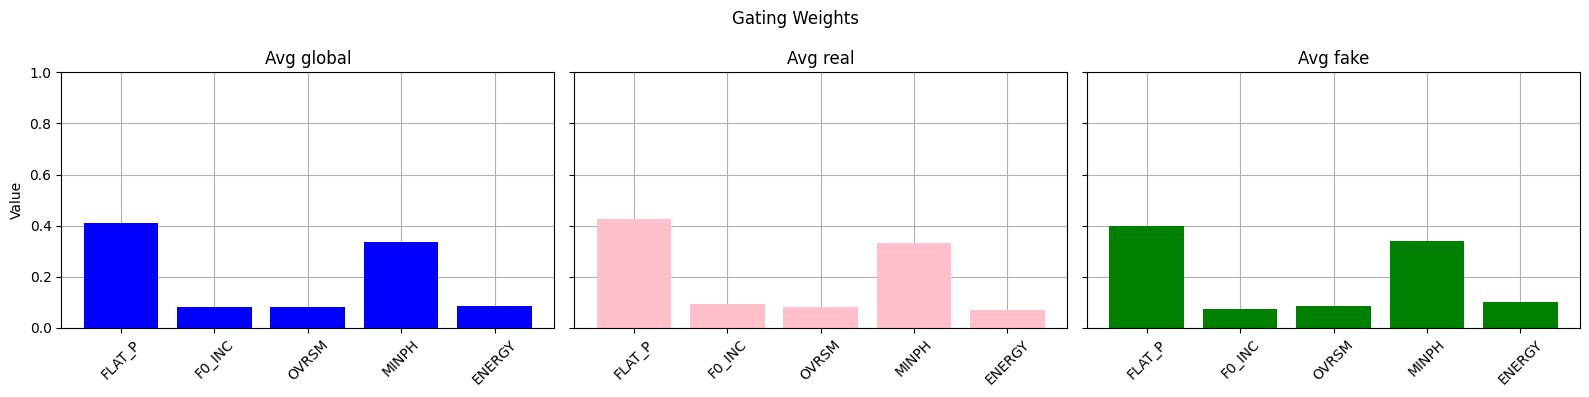

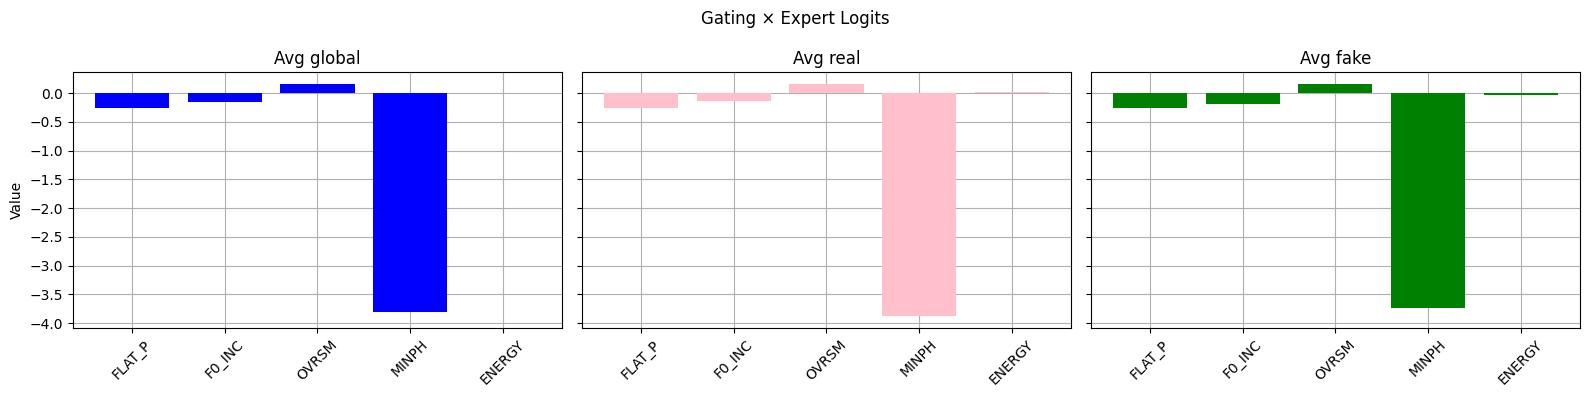

-----------------------------------
A11

Individual Experts' Performance:
AUC: 46.13%, EER: 52.39%
AUC: 35.13%, EER: 59.19%
AUC: 45.27%, EER: 56.11%
AUC: 78.28%, EER: 29.33%
AUC: 82.28%, EER: 25.19%

MoE Performance:
AUC: 78.17%, EER: 28.48%
Loaded 1902 samples
Real mean score: -4.0981
Fake mean score: 1.4695



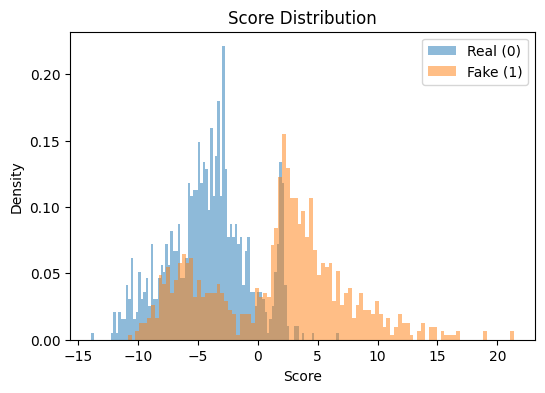

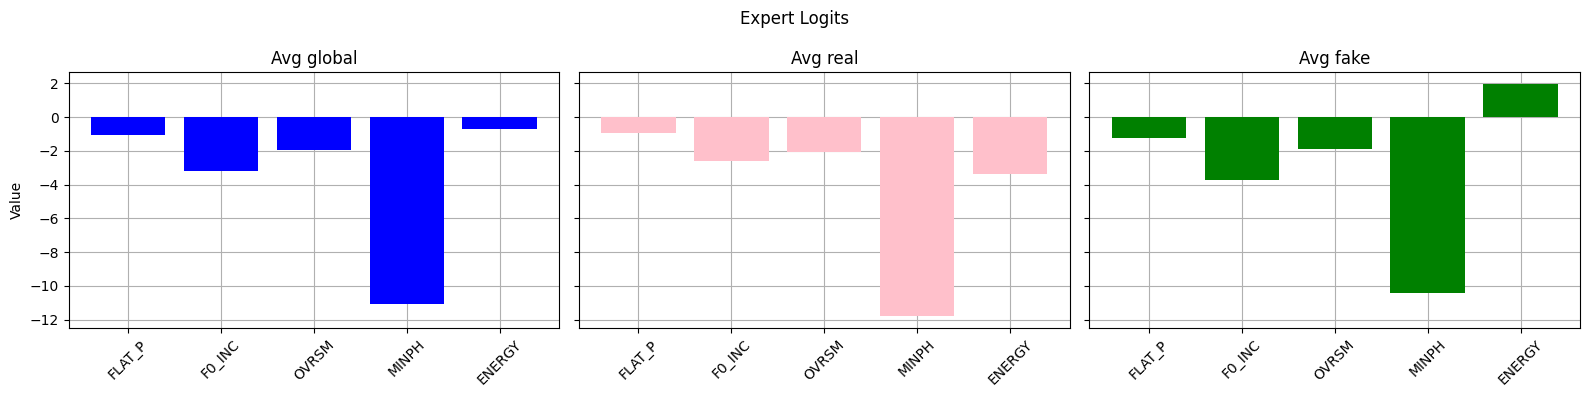

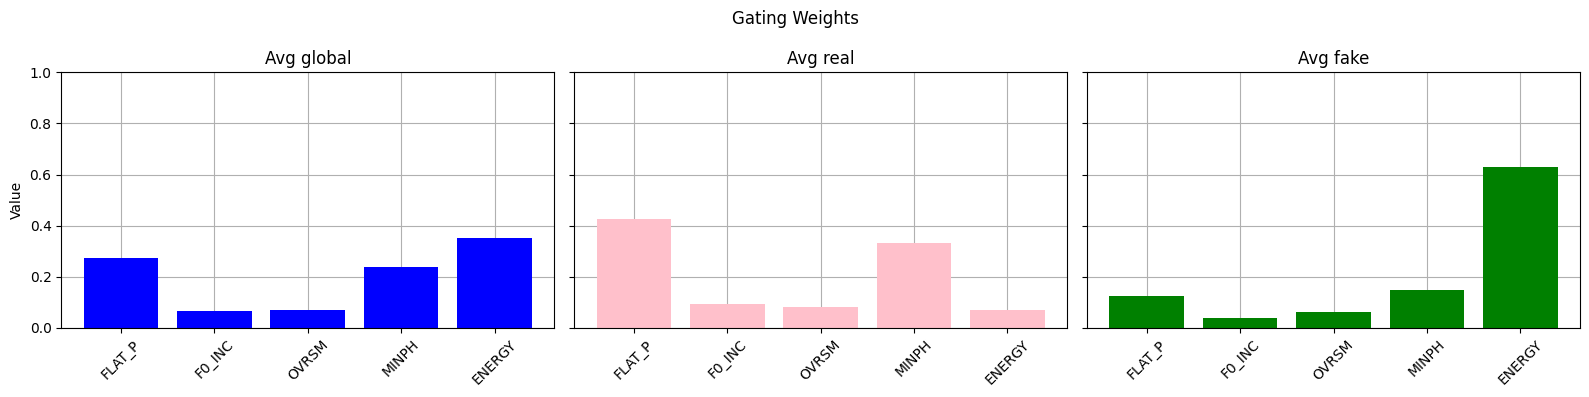

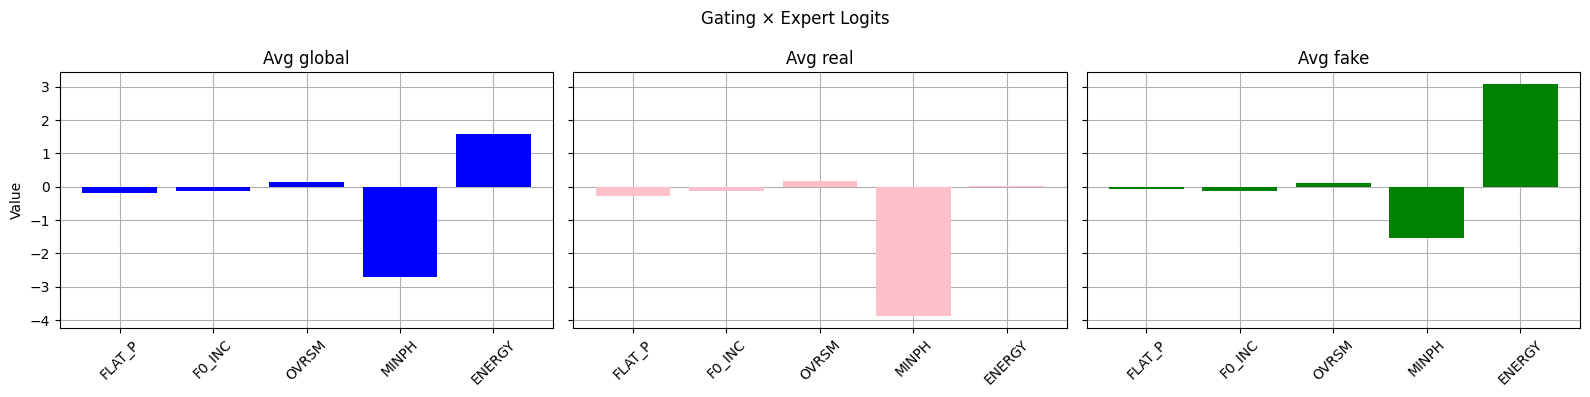

-----------------------------------
A12

Individual Experts' Performance:
AUC: 52.39%, EER: 48.14%
AUC: 39.70%, EER: 56.64%
AUC: 39.32%, EER: 58.45%
AUC: 59.22%, EER: 43.78%
AUC: 86.44%, EER: 18.92%

MoE Performance:
AUC: 85.74%, EER: 20.51%
Loaded 1876 samples
Real mean score: -4.0981
Fake mean score: 6.3197



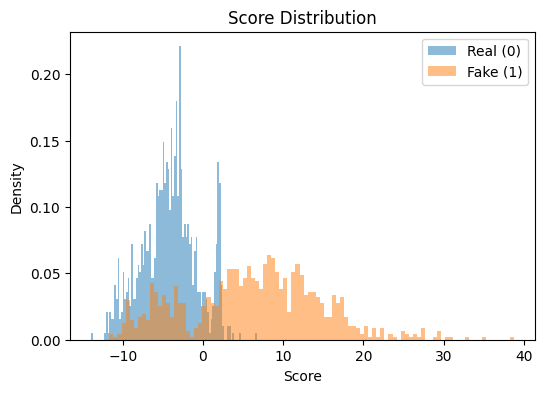

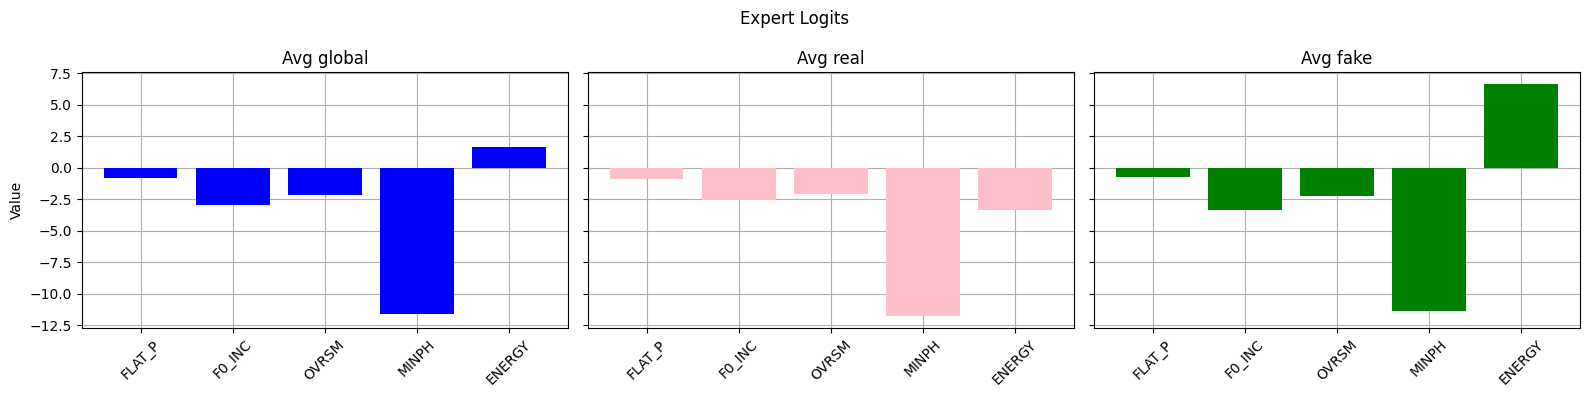

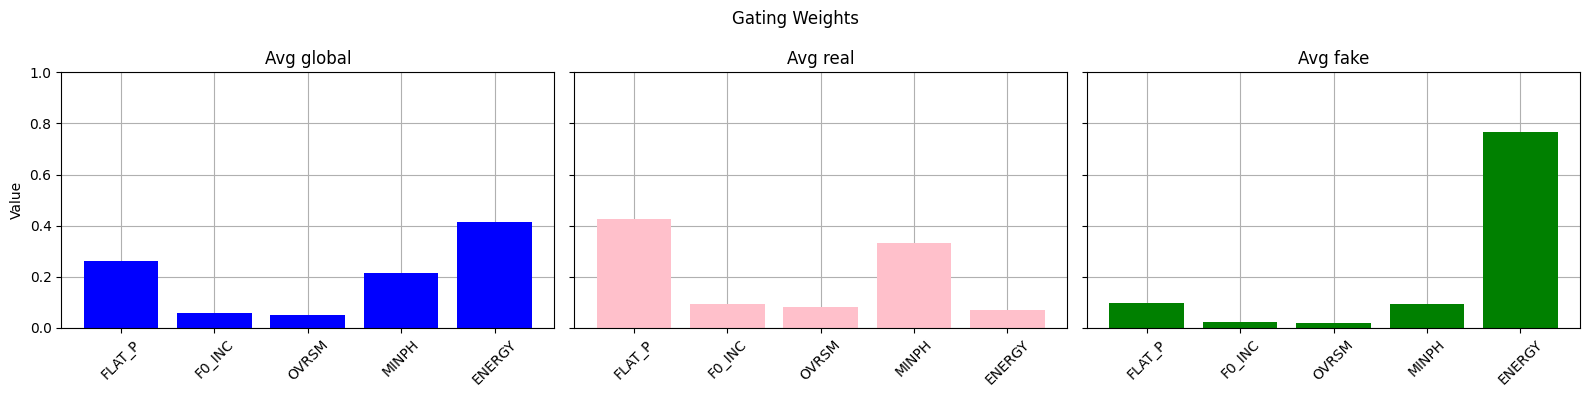

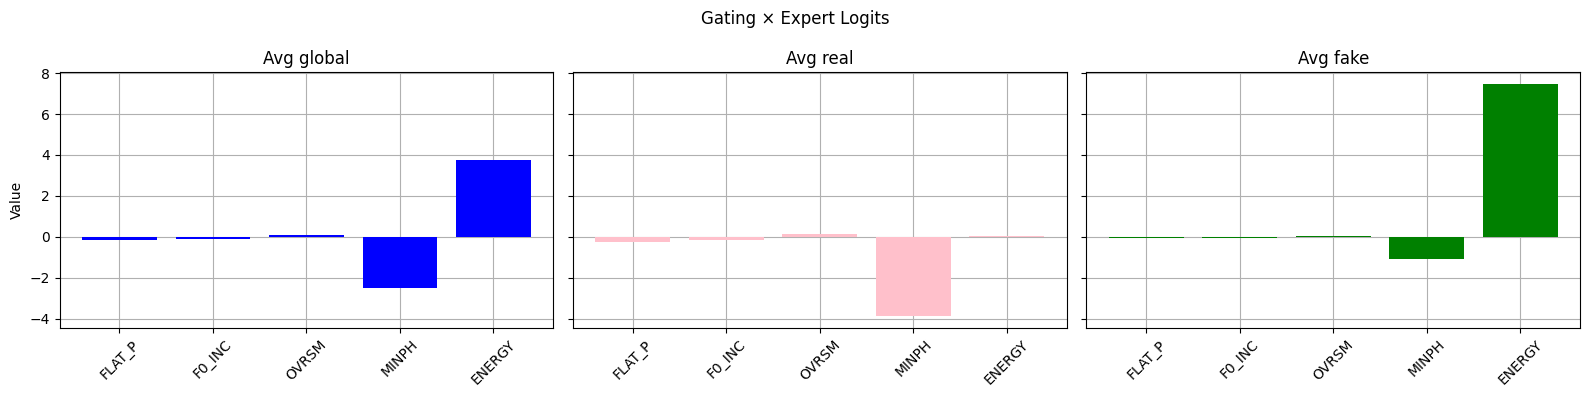

-----------------------------------


In [17]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/{g}"
    model_name = "best_frozen_5_exp_new"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True, plot=True)
    print("-----------------------------------")


Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 63.86%, EER: 38.79%

MoE Performance:
AUC: 37.68%, EER: 63.12%


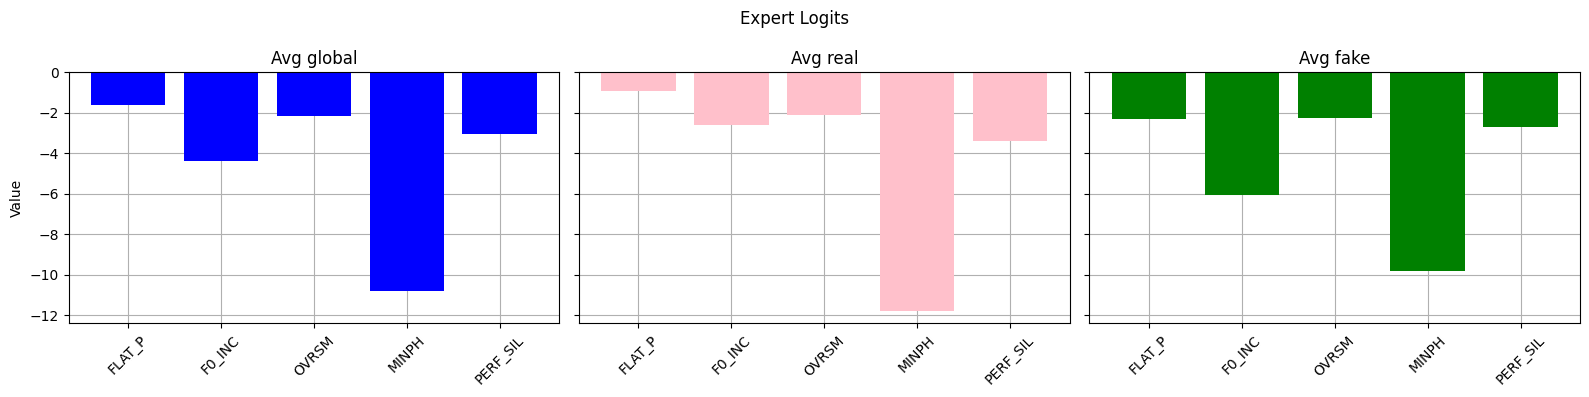

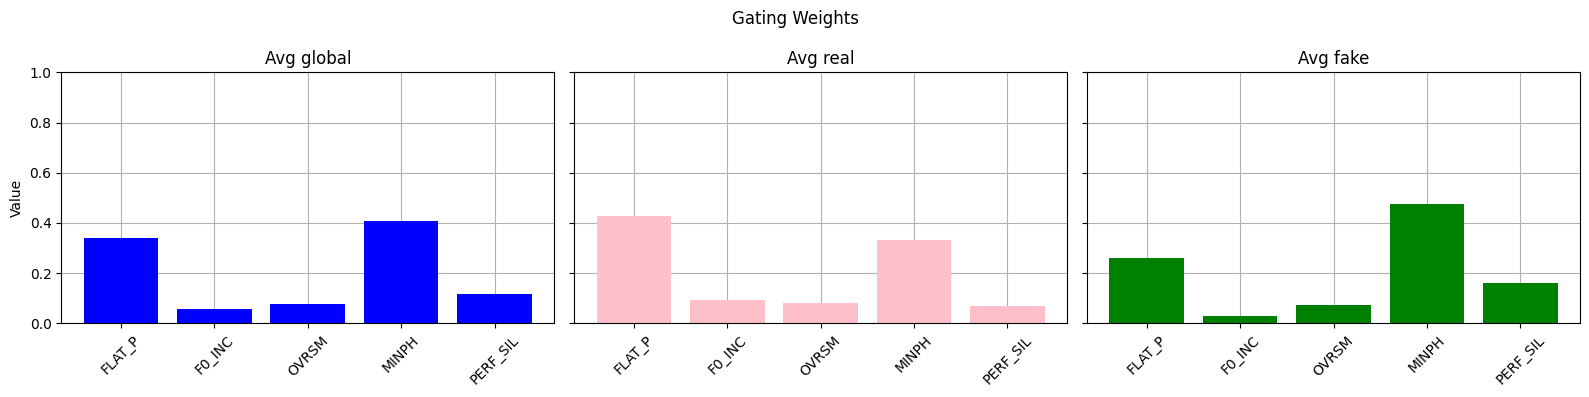

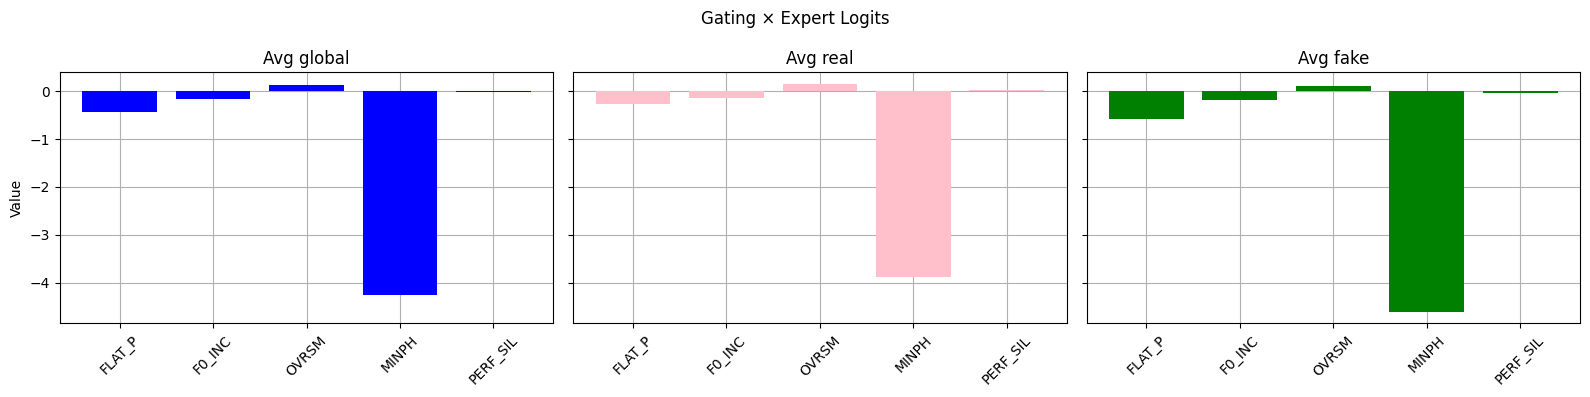


Average Expert Stats + Gate Weights
Expert |  Overall   |   Real     |   Fake     |  Δ(F-R)    | Gate_R  | Gate_F
-----------------------------------------------------------------------------------------------
  0    |  -1.626269 |  -0.925251 |  -2.286585 |  -1.361334 |  0.4263 |  0.2606
  1    |  -4.378347 |  -2.612678 |  -6.041510 |  -3.428833 |  0.0922 |  0.0279
  2    |  -2.159600 |  -2.084624 |  -2.230222 |  -0.145597 |  0.0809 |  0.0728
  3    | -10.774311 | -11.801059 |  -9.807181 |   1.993877 |  0.3315 |  0.4765
  4    |  -3.046554 |  -3.396173 |  -2.717235 |   0.678938 |  0.0691 |  0.1622


In [18]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/A07"
model_name = "best_frozen_5_exp_new"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
e, g, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, plot=True)

print("\nAverage Expert Stats + Gate Weights")
print("Expert |  Overall   |   Real     |   Fake     |  Δ(F-R)    | Gate_R  | Gate_F")
print("-" * 95)

for j in range(len(e[0])):
    overall = e[0][j]
    real = e[1][j]
    fake = e[2][j]
    delta = fake - real

    gate_real = g[1][j]
    gate_fake = g[2][j]

    print(f"{j:^6} | "
          f"{overall:10.6f} | "
          f"{real:10.6f} | "
          f"{fake:10.6f} | "
          f"{delta:10.6f} | "
          f"{gate_real:7.4f} | "
          f"{gate_fake:7.4f}")